# Map of Catalonia by comarca: forest hectares burned (2011-2024)

We join the fires table (CSV) with the comarca outlines (JSON) and draw a map with a colour scale.

## 0) Libraries and paths

In [16]:
import pandas as pd                
import geopandas as gpd            
import matplotlib.pyplot as plt    

## 1) Read and prepare the fires table

In [14]:
# Read the CSV; numbers look like "5.621,80", so the dot separates thousands and the comma marks decimals
fires = pd.read_csv("../data/Incendis_forestals_a_Catalunya._Anys_2011-2024_20261116.csv",decimal=",", thousands=".",)

# The comarca code in the CSV is a number without leading zero (8), but in the map it is text with two digits ("08")
# I turn it into text and pad it with zeros on the left until it has 2 digits
fires["code"] = fires["CODI COMARCA"].astype(str).str.zfill(2)

# Each row is one fire, but I want one total per comarca
# Group by comarca and add up the burned forest hectares (column HAFORESTAL)
total = fires.groupby("code")["HAFORESTAL"].sum().reset_index()

# Give the summed column a clearer name
total = total.rename(columns={"HAFORESTAL": "ha_burned"})


## 2) Read the map and join it with the data

In [13]:
# Read the file with the comarca outlines
map_com = gpd.read_file(("../data/divisions-administratives-v2r1-comarques-250000-20250730.json"))

# Convert to Catalonia's coordinate system (EPSG:25831) so the map is not distorted
map_com = map_com.to_crs(25831)

# Join the map with my totals using the comarca code 
# how="left" keeps every comarca even if it has no data; validate prevents duplicated rows
map_com = map_com.merge(total, left_on="CODICOMAR", right_on="code", how="left", validate="one_to_one")

# We check if there is a comarque with 0 fires 
print(map_com.loc[map_com["ha_burned"].isna(), "NOMCOMAR"].tolist())

['Lluçanès']


## 3) Draw the map

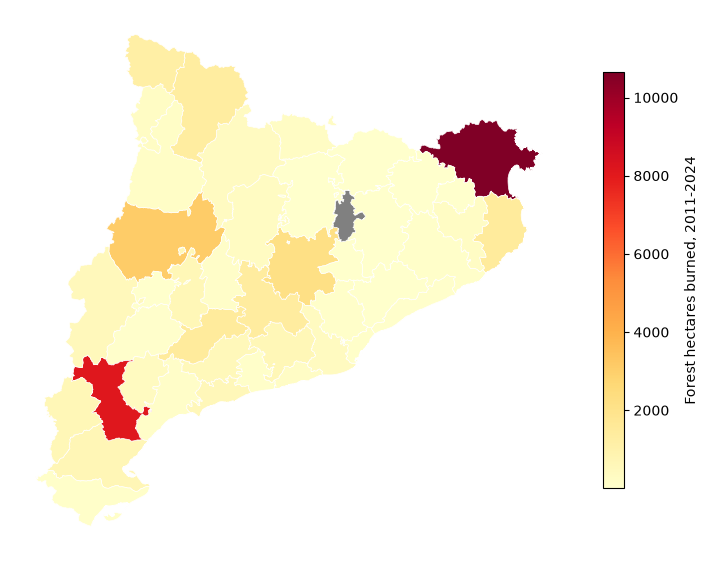

In [17]:
fig, ax = plt.subplots(figsize=(9, 9))

# Draw the map, colouring each comarca by its burned hectares
map_com.plot(
    column="ha_burned",                   # the column that decides the colour
    cmap="YlOrRd",                        # scale from yellow (little) to dark red (a lot)
    legend=True,                          # add the colour bar
    legend_kwds={"label": "Forest hectares burned, 2011-2024", "shrink": 0.6},  # colour bar text and size
    missing_kwds={"color": "grey"},  # comarques with no data are drawn in light grey
    edgecolor="white",                    # white border between comarques
    linewidth=0.5,                        # border thickness
    ax=ax,                                # tell it which area to draw on
)

fig.savefig("fires_map_com.png", dpi=200, bbox_inches="tight")
ax.set_axis_off()
plt.show()